In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


def read_triplicate_data(filepath):
    df = pd.read_csv(
        filepath,
        sep=";",
        index_col=0,
        header=0
    ).T

    df = df.replace(",", ".", regex=True).astype(float)

    return df


DATA_FILE = Path(
    "/home/nrz989/Documents/ASMT dynamic analysis/ASMT_data_900.csv"
)

df = read_triplicate_data(DATA_FILE)

print("Raw input data:")
print(df)

Raw input data:
              Conc NAS  10 uM SAM  30 uM SAM  60 uM SAM  90 uM SAM  \
SAM uM             NaN     10.000     30.000     60.000     90.000   
20 uM NAS         20.0  10456.832  16661.958  21097.162  21393.712   
20 uM NAS.1       20.0  10130.159  16073.387  23722.691  22141.186   
20 uM NAS.2       20.0  10986.865  16796.832  21666.290  20692.904   
50 uM NAS         50.0  13276.207  23178.064  18503.611  27524.652   
50 uM NAS.1       50.0  12453.029  22247.486  30189.960  28581.844   
50 uM NAS.2       50.0  14279.330  22680.381  25417.369  27359.000   
100 uM NAS       100.0  16962.929  24447.553  26046.429  29269.230   
100 uM NAS.1     100.0  16466.155  25384.658  31793.854  25624.634   
100 uM NAS.2     100.0  16451.974  25490.757  30692.610  28227.104   
300 uM NAS       300.0  14448.257  21146.817  19722.660  19265.856   
300 uM NAS.1     300.0  14430.490  21717.960  20562.071  22668.389   
300 uM NAS.2     300.0  14008.690  22984.760  19928.631  19573.923   
600 

In [2]:
# Group triplicate measurements by NAS concentration
grouped = df.groupby(df.columns[0])

# Calculate mean peak area and sample standard deviation
areas_averaged = grouped.mean()
areas_sd = grouped.std(ddof=1)

# Display mean peak areas and SD
print("Average peak areas:")
print(areas_averaged.round(1))

print("\nPeak area SD:")
print(areas_sd.round(1))

Average peak areas:
          10 uM SAM  30 uM SAM  60 uM SAM  90 uM SAM  140 uM SAM  200 uM SAM
Conc NAS                                                                    
20.0        10524.6    16510.7    22162.0    21409.3     20345.6     24358.9
50.0        13336.2    22702.0    24703.6    27821.8     31399.9     29093.6
100.0       16627.0    25107.7    29511.0    27707.0     29026.9     27826.5
300.0       14295.8    21949.8    20071.1    20502.7     19862.6     15263.3
600.0       12489.0     6592.9    14308.6     9907.0      9605.1     10348.3
900.0        9730.2     4661.6    10588.4     9474.4      7095.5      7196.3

Peak area SD:
          10 uM SAM  30 uM SAM  60 uM SAM  90 uM SAM  140 uM SAM  200 uM SAM
Conc NAS                                                                    
20.0          432.4      384.7     1381.2      724.3      2589.5      1700.5
50.0          914.6      465.7     5875.8      663.4       954.5      1086.0
100.0         291.0      574.1     3050.5

In [3]:
# Standard curve
# Peak area = 6.4189 * melatonin_nM + 156.4156

standard_slope = 6.4189
standard_intercept = 156.4156
reaction_time_min = 15.0

# Convert peak area to melatonin concentration.
# The standards underwent the same dilution and sample-processing procedure，so no additional dilution correction is required.

melatonin_nM = (
    areas_averaged - standard_intercept
) / standard_slope

# Convert peak-area SD to melatonin concentration SD.

melatonin_nM_sd = (
    areas_sd / standard_slope
)

# Calculate velocity from melatonin formation over the 15 min reaction period.
# Convert nM/min to µM/min.

velocities = (
    melatonin_nM
    / reaction_time_min
    / 1000.0
)

velocities_sd = (
    melatonin_nM_sd
    / reaction_time_min
    / 1000.0
)

print("Velocities, µM/min:")
print(velocities.round(4))

print("\nVelocity SD, µM/min:")
print(velocities_sd.round(4))

Velocities, µM/min:
          10 uM SAM  30 uM SAM  60 uM SAM  90 uM SAM  140 uM SAM  200 uM SAM
Conc NAS                                                                    
20.0         0.1077     0.1699     0.2286     0.2207      0.2097      0.2514
50.0         0.1369     0.2342     0.2549     0.2873      0.3245      0.3005
100.0        0.1711     0.2591     0.3049     0.2861      0.2998      0.2874
300.0        0.1469     0.2263     0.2068     0.2113      0.2047      0.1569
600.0        0.1281     0.0668     0.1470     0.1013      0.0981      0.1059
900.0        0.0994     0.0468     0.1083     0.0968      0.0721      0.0731

Velocity SD, µM/min:
          10 uM SAM  30 uM SAM  60 uM SAM  90 uM SAM  140 uM SAM  200 uM SAM
Conc NAS                                                                    
20.0         0.0045     0.0040     0.0143     0.0075      0.0269      0.0177
50.0         0.0095     0.0048     0.0610     0.0069      0.0099      0.0113
100.0        0.0030     0.0060    

In [4]:
# Prepare velocity matrix for kinetic analysis

V = velocities.copy()
V_sd = velocities_sd.copy()

# SAM concentrations used in the kinetic matrix

c_SAM = np.array([
    10.,
    30.,
    60.,
    90.,
    140.,
    200.
])

V.columns = c_SAM
V_sd.columns = c_SAM

# NAS concentrations are taken from the dataframe index

c_NAS = V.index.to_numpy(dtype=float)

x_SAM = V.columns.to_numpy(dtype=float)
y_NAS = V.index.to_numpy(dtype=float)

# Create the two-dimensional SAM/NAS concentration grid

X, Y = np.meshgrid(
    x_SAM,
    y_NAS
)

# Mean velocity and SD matrices

Z = V.values
Z_sd = V_sd.values

# Flatten the concentration grid and velocity matrix
# for global nonlinear fitting

xdata = np.column_stack(
    (
        X.flatten(),
        Y.flatten()
    )
)

zdata = Z.flatten()

print("Velocity matrix V:")
print(V.round(4))

print("\nVelocity SD matrix:")
print(V_sd.round(4))

print("\nSAM concentrations:")
print(x_SAM)

print("\nNAS concentrations:")
print(y_NAS)

print("\nxdata first 10 rows:")
print(xdata[:10])

print("\nzdata first 10 values:")
print(zdata[:10])

Velocity matrix V:
           10.0    30.0    60.0    90.0    140.0   200.0
Conc NAS                                                
20.0      0.1077  0.1699  0.2286  0.2207  0.2097  0.2514
50.0      0.1369  0.2342  0.2549  0.2873  0.3245  0.3005
100.0     0.1711  0.2591  0.3049  0.2861  0.2998  0.2874
300.0     0.1469  0.2263  0.2068  0.2113  0.2047  0.1569
600.0     0.1281  0.0668  0.1470  0.1013  0.0981  0.1059
900.0     0.0994  0.0468  0.1083  0.0968  0.0721  0.0731

Velocity SD matrix:
           10.0    30.0    60.0    90.0    140.0   200.0
Conc NAS                                                
20.0      0.0045  0.0040  0.0143  0.0075  0.0269  0.0177
50.0      0.0095  0.0048  0.0610  0.0069  0.0099  0.0113
100.0     0.0030  0.0060  0.0317  0.0195  0.0300  0.0127
300.0     0.0026  0.0098  0.0045  0.0195  0.0121  0.0239
600.0     0.0045  0.0061  0.0088  0.0088  0.0202  0.0210
900.0     0.0044  0.0037  0.0068  0.0065  0.0140  0.0084

SAM concentrations:
[ 10.  30.  60.  90. 140. 2

In [5]:
# global kinetic model comparison
#
# A = SAM
# B = NAS
#
# Two candidate models:
# 1. Ordered BiBi
# 2. Ordered BiBi + AB^2
#
# Primary fitting:
# - unweighted nonlinear least squares
# - positive kinetic parameters
# - 100 multi-start fits
# - AICc and BIC for model comparison
#
# K0 is fitted as the composite constant:
# K0 = Kia_SAM * Km_NAS

import warnings
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, OptimizeWarning


# Input data
xdata = np.asarray(xdata, dtype=float)
zdata = np.asarray(zdata, dtype=float)

if not np.all(np.isfinite(xdata)):
    raise ValueError("xdata contains non-finite values.")

if not np.all(np.isfinite(zdata)):
    raise ValueError("zdata contains non-finite values.")


# Model 1: Sequential BiBi
#
# v = Vmax*A*B /
#     (K0 + Km_NAS*A + Km_SAM*B + A*B)
def Ordered_bibi(
    X,
    Vmax,
    K0,
    Km_NAS,
    Km_SAM
):
    A = X[:, 0]
    B = X[:, 1]

    denominator = (
        K0
        + Km_NAS * A
        + Km_SAM * B
        + A * B
    )

    return Vmax * A * B / denominator


# Model 2: Sequential BiBi + AB^2

def Ordered_bibi_AB2(
    X,
    Vmax,
    K0,
    Km_NAS,
    Km_SAM,
    Ki_NAS_app
):
    A = X[:, 0]
    B = X[:, 1]

    denominator = (
        K0
        + Km_NAS * A
        + Km_SAM * B
        + A * B
        + A * B**2 / Ki_NAS_app
    )

    return Vmax * A * B / denominator


# Model specifications

N_STARTS = 100
RANDOM_SEED = 2026

Vmax_start = zdata.max() * 1.5

model_specs = [
    {
        "name": "Ordered BiBi",
        "function": Ordered_bibi,
        "parameters": [
            "Vmax",
            "K0",
            "Km_NAS",
            "Km_SAM"
        ],
        "p0": [
            Vmax_start,
            150.0,
            10.0,
            15.0
        ]
    },

    {
        "name": "Ordered BiBi + AB2",
        "function": Ordered_bibi_AB2,
        "parameters": [
            "Vmax",
            "K0",
            "Km_NAS",
            "Km_SAM",
            "Ki_NAS_app"
        ],
        "p0": [
            Vmax_start,
            150.0,
            10.0,
            15.0,
            400.0
        ]
    }
]


# Information criteria

def calculate_information_criteria(
    rss,
    n,
    p
):
    """
    Calculate AICc and BIC from the Gaussian likelihood.

    p is the number of fitted kinetic parameters.
    One additional parameter is counted for residual variance
    when calculating the information criteria.
    """

    rss = max(
        rss,
        np.finfo(float).tiny
    )

    k_ic = p + 1

    minus_2_log_likelihood = (
        n
        * (
            np.log(2.0 * np.pi)
            + 1.0
            + np.log(rss / n)
        )
    )

    aic = (
        minus_2_log_likelihood
        + 2.0 * k_ic
    )

    if n > k_ic + 1:
        aicc = (
            aic
            + (
                2.0
                * k_ic
                * (k_ic + 1)
                / (n - k_ic - 1)
            )
        )
    else:
        aicc = np.nan

    bic = (
        minus_2_log_likelihood
        + k_ic * np.log(n)
    )

    return aicc, bic


# Multi-start fitting

def fit_model_multistart(
    model,
    name,
    parameter_names,
    base_p0,
    random_seed
):
    rng = np.random.default_rng(
        random_seed
    )

    base_p0 = np.asarray(
        base_p0,
        dtype=float
    )

    n_parameters = len(
        base_p0
    )

    lower_bounds = np.full(
        n_parameters,
        1e-12
    )

    upper_bounds = np.full(
        n_parameters,
        np.inf
    )

    starting_points = [
        base_p0
    ]

    for _ in range(N_STARTS - 1):

        scale = 10.0 ** rng.uniform(
            -2.0,
            2.0,
            size=n_parameters
        )

        starting_points.append(
            base_p0 * scale
        )

    successful_fits = []

    for start in starting_points:

        try:
            with warnings.catch_warnings():

                warnings.simplefilter(
                    "ignore",
                    OptimizeWarning
                )

                popt, pcov = curve_fit(
                    model,
                    xdata,
                    zdata,
                    p0=start,
                    bounds=(
                        lower_bounds,
                        upper_bounds
                    ),
                    method="trf",
                    x_scale="jac",
                    ftol=1e-10,
                    xtol=1e-10,
                    gtol=1e-10,
                    max_nfev=100000
                )

            prediction = model(
                xdata,
                *popt
            )

            residuals = (
                zdata
                - prediction
            )

            rss = np.sum(
                residuals**2
            )

            if np.isfinite(rss):

                successful_fits.append(
                    (
                        rss,
                        popt,
                        pcov,
                        prediction,
                        residuals
                    )
                )

        except (
            RuntimeError,
            ValueError,
            FloatingPointError
        ):
            continue

    if not successful_fits:

        raise RuntimeError(
            f"No successful fit for {name}."
        )

    successful_fits.sort(
        key=lambda x: x[0]
    )

    (
        rss,
        popt,
        pcov,
        prediction,
        residuals
    ) = successful_fits[0]


    # Parameter standard errors

    if (
        pcov is not None
        and np.all(
            np.isfinite(pcov)
        )
    ):

        se = np.sqrt(
            np.diag(pcov)
        )

    else:

        se = np.full(
            len(popt),
            np.nan
        )


    with np.errstate(
        divide="ignore",
        invalid="ignore"
    ):

        relative_se = (
            se / np.abs(popt)
        )


    # Check convergence from independent starting points

    rss_tolerance = max(
        1e-12,
        abs(rss) * 1e-6
    )

    near_best_starts = sum(
        abs(fit[0] - rss)
        <= rss_tolerance
        for fit
        in successful_fits
    )


    n = len(zdata)
    p = len(popt)

    aicc, bic = (
        calculate_information_criteria(
            rss,
            n,
            p
        )
    )


    return {
        "Model": name,
        "Function": model,
        "Parameter_names": parameter_names,
        "Parameters": popt,
        "SE": se,
        "Relative_SE": relative_se,
        "RSS": rss,
        "AICc": aicc,
        "BIC": bic,
        "Successful_starts": len(successful_fits),
        "Near_best_starts": near_best_starts,
        "Prediction": prediction,
        "Residuals": residuals
    }


# Fit both models

results = []

for i, spec in enumerate(
    model_specs
):

    print(
        f"Fitting {i + 1}/{len(model_specs)}: "
        f"{spec['name']}"
    )

    result = fit_model_multistart(
        model=spec["function"],
        name=spec["name"],
        parameter_names=spec["parameters"],
        base_p0=spec["p0"],
        random_seed=RANDOM_SEED + i
    )

    results.append(
        result
    )

# Model comparison
summary_rows = []

for result in results:

    summary_rows.append(
        {
            "Model": result["Model"],
            "p": len(result["Parameters"]),
            "RSS": result["RSS"],
            "AICc": result["AICc"],
            "BIC": result["BIC"]
        }
    )


summary_df = pd.DataFrame(
    summary_rows
)


summary_df["Delta_AICc"] = (
    summary_df["AICc"]
    - summary_df["AICc"].min()
)


summary_df["Delta_BIC"] = (
    summary_df["BIC"]
    - summary_df["BIC"].min()
)


summary_df = (
    summary_df
    .sort_values("AICc")
    .reset_index(drop=True)
)


# Reorder columns

summary_df = summary_df[
    [
        "Model",
        "p",
        "RSS",
        "AICc",
        "Delta_AICc",
        "BIC",
        "Delta_BIC"
    ]
]


print(
    "\nGlobal kinetic model comparison:"
)

print(
    summary_df.round(
        {
            "RSS": 4,
            "AICc": 2,
            "Delta_AICc": 2,
            "BIC": 2,
            "Delta_BIC": 2
        }
    ).to_string(
        index=False
    )
)

# Select final model
best_AICc_model = (
    summary_df.iloc[0]["Model"]
)

best_BIC_model = (
    summary_df.loc[
        summary_df["BIC"].idxmin(),
        "Model"
    ]
)


if (
    best_AICc_model
    == best_BIC_model
):

    selected_model_name = (
        best_AICc_model
    )

    selected_result = next(
        result
        for result in results
        if result["Model"]
        == selected_model_name
    )

    print(
        "\nSelected model:"
    )

    print(
        selected_model_name
    )

else:

    selected_model_name = None
    selected_result = None

    print(
        "\nAICc and BIC do not select "
        "the same model."
    )


# Parameter estimates

parameter_units = {
    "Vmax": "µM/min",
    "K0": "µM²",
    "Km_NAS": "µM",
    "Km_SAM": "µM",
    "Ki_NAS_app": "µM"
}


parameter_rows = []

for result in results:

    print(
        "\n"
        + "=" * 70
    )

    print(
        result["Model"]
    )

    print(
        "=" * 70
    )

    for (
        name,
        estimate,
        se,
        relative_se
    ) in zip(
        result["Parameter_names"],
        result["Parameters"],
        result["SE"],
        result["Relative_SE"]
    ):

        unit = parameter_units.get(
            name,
            ""
        )

        print(
            f"{name:12s} "
            f"= {estimate:10.4g} "
            f"± {se:10.4g} "
            f"{unit:7s} "
            f"(RSE = "
            f"{relative_se * 100:.1f}%)"
        )

        parameter_rows.append(
            {
                "Model": result["Model"],
                "Parameter": name,
                "Estimate": estimate,
                "SE": se,
                "Relative_SE": relative_se
            }
        )


parameter_df = pd.DataFrame(
    parameter_rows
)


# Save results

summary_df.to_csv(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "final_two_model_comparison.csv",
    index=False
)

parameter_df.to_csv(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "final_two_model_parameters.csv",
    index=False
)


print(
    "\nResults saved."
)

Fitting 1/2: Ordered BiBi
Fitting 2/2: Ordered BiBi + AB2

Global kinetic model comparison:
             Model  p    RSS    AICc  Delta_AICc     BIC  Delta_BIC
Ordered BiBi + AB2  5 0.0162 -160.27        0.00 -153.67       0.00
      Ordered BiBi  4 0.2082  -71.34       88.93  -65.42      88.24

Selected model:
Ordered BiBi + AB2

Ordered BiBi
Vmax         =     0.2114 ±    0.02868 µM/min  (RSE = 13.6%)
K0           =      1e-12 ±      241.9 µM²     (RSE = 24193155115839416.0%)
Km_NAS       =      1e-12 ±      6.053 µM      (RSE = 605320610052177.9%)
Km_SAM       =      6.055 ±      5.985 µM      (RSE = 98.8%)

Ordered BiBi + AB2
Vmax         =     0.5628 ±    0.06964 µM/min  (RSE = 12.4%)
K0           =      681.5 ±        247 µM²     (RSE = 36.2%)
Km_NAS       =      20.17 ±      6.928 µM      (RSE = 34.3%)
Km_SAM       =      5.567 ±      4.487 µM      (RSE = 80.6%)
Ki_NAS_app   =      165.4 ±      31.46 µM      (RSE = 19.0%)

Results saved.


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Final selected model:
# Ordered BiBi + AB2
# A = SAM
# B = NAS

def Ordered_bibi_nas_inhibition(X, Vmax, Ks_A, K_AB, Ki_EAB2):
    A = X[:, 0]
    B = X[:, 1]
    return Vmax * A * B / (
        Ks_A * K_AB
        + K_AB * A
        + A * B
        + A * B**2 / Ki_EAB2
    )

Model used for plotting: Ordered BiBi + AB2


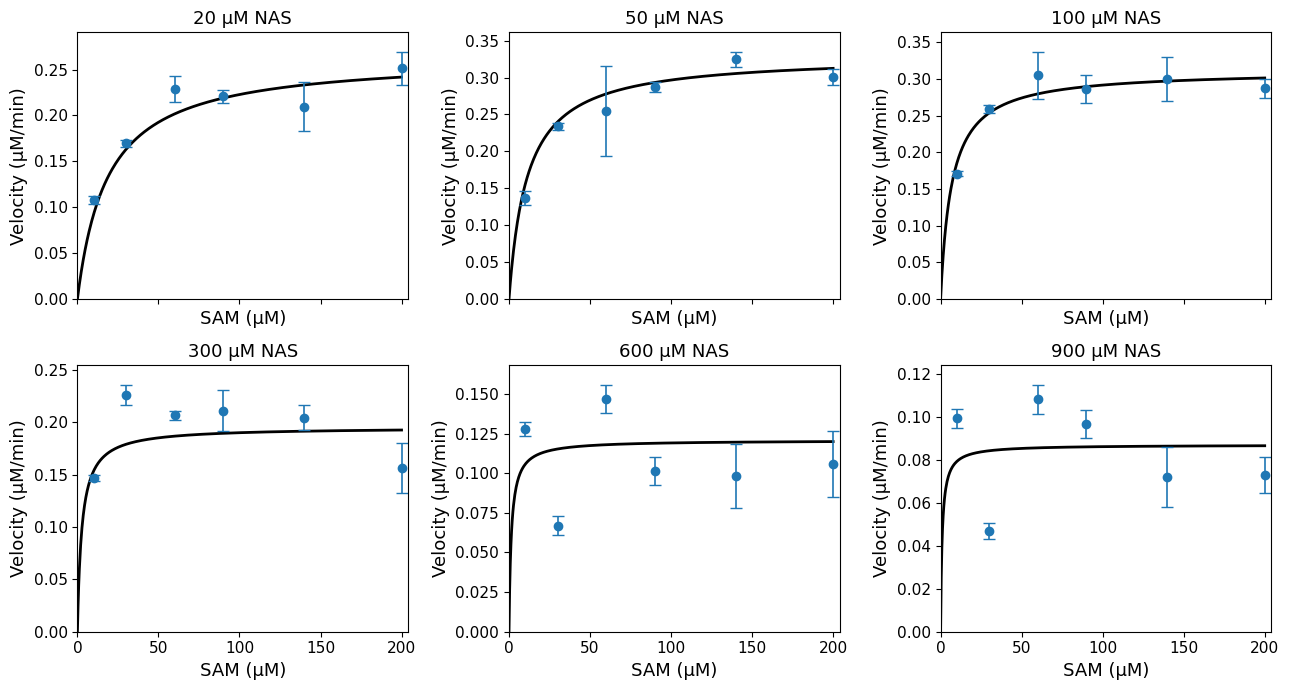

In [7]:
# Figure A
# Velocity versus SAM at fixed NAS
# Independent y-axis scaling
# Lines are predictions from the selected global model

if selected_result is None:
    raise RuntimeError(
        "No selected global model is available."
    )

selected_model = selected_result["Function"]
selected_parameters = selected_result["Parameters"]

print(
    "Model used for plotting:",
    selected_result["Model"]
)


colors = plt.cm.tab10(
    np.linspace(
        0,
        1,
        len(y_NAS)
    )
)

markers = [
    "o",
    "s",
    "^",
    "v",
    "D",
    "P"
]


# Model curves may extend to zero substrate concentration.
# No experimental point is added at zero.

sam_smooth = np.linspace(
    0.0,
    x_SAM.max(),
    500
)


fig, axes = plt.subplots(
    2,
    3,
    figsize=(13, 7),
    sharex=True,
    sharey=False
)

axes = axes.flatten()


for i, nas in enumerate(
    y_NAS
):

    ax = axes[i]

    # Observed mean velocity and SD
    y_obs = V.loc[nas].values
    y_sd = V_sd.loc[nas].values


    # Global-model prediction
    prediction_input = np.column_stack(
        (
            sam_smooth,
            np.full_like(
                sam_smooth,
                nas
            )
        )
    )

    y_fit = selected_model(
        prediction_input,
        *selected_parameters
    )


    # Global fitted curve
    ax.plot(
        sam_smooth,
        y_fit,
        color="black",
        linewidth=2
    )


    # Experimental observations
    ax.errorbar(
        x_SAM,
        y_obs,
        yerr=y_sd,
        fmt="o",
        markersize=6,
        capsize=4,
        linewidth=1.2
    )


    ax.set_title(
        f"{nas:g} µM NAS",
        fontsize=13
    )

    ax.set_xlabel(
        "SAM (µM)",
        fontsize=13
    )

    ax.set_ylabel(
        "Velocity (µM/min)",
        fontsize=13
    )

    ax.tick_params(
        axis="both",
        labelsize=11
    )


    # Independent y-axis range for each panel
    y_all = np.concatenate(
        (
            y_obs - y_sd,
            y_obs + y_sd,
            y_fit
        )
    )

    y_max = np.max(
        y_all
    )

    ax.set_ylim(
        0,
        y_max * 1.08
    )

    ax.set_xlim(
        0,
        x_SAM.max() * 1.02
    )


plt.tight_layout()


plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "global_fit_fixed_NAS_velocity_vs_SAM_independent_y.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "global_fit_fixed_NAS_velocity_vs_SAM_independent_y.pdf",
    bbox_inches="tight"
)


plt.show()

Model used for plotting: Ordered BiBi + AB2


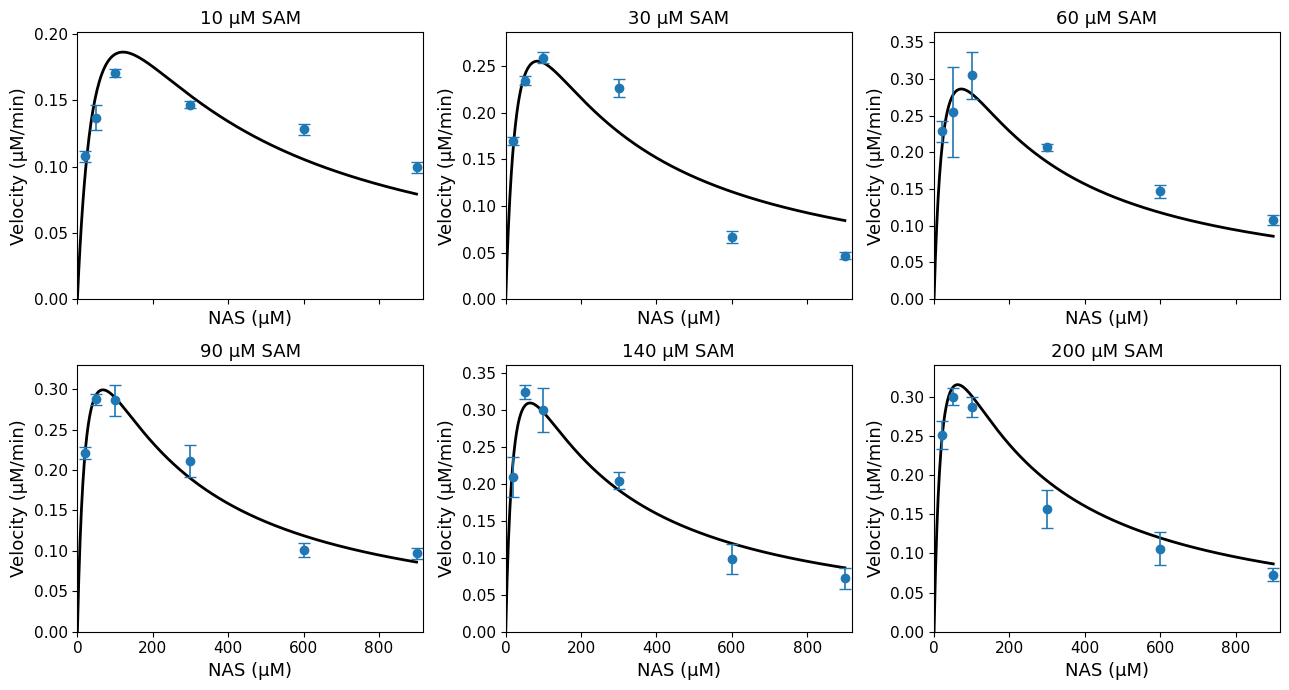

In [8]:
# Figure B
# Velocity versus NAS at fixed SAM
# Independent y-axis scaling
# Lines are predictions from the selected global model

if selected_result is None:
    raise RuntimeError(
        "No selected global model is available."
    )

selected_model = selected_result["Function"]
selected_parameters = selected_result["Parameters"]

print(
    "Model used for plotting:",
    selected_result["Model"]
)


# Smooth NAS range for model prediction
# The model curve extends to zero NAS concentration,
# but no experimental point is added at zero.

nas_smooth = np.linspace(
    0.0,
    y_NAS.max(),
    500
)


fig, axes = plt.subplots(
    2,
    3,
    figsize=(13, 7),
    sharex=True,
    sharey=False
)

axes = axes.flatten()


for i, sam in enumerate(
    x_SAM
):

    ax = axes[i]


    # Observed mean velocity and SD
    y_obs = V[sam].values
    y_sd = V_sd[sam].values


     # Prediction from the globally selected model
    prediction_input = np.column_stack(
        (
            np.full_like(
                nas_smooth,
                sam
            ),
            nas_smooth
        )
    )

    y_fit = selected_model(
        prediction_input,
        *selected_parameters
    )


     # Global fitted curve
    ax.plot(
        nas_smooth,
        y_fit,
        color="black",
        linewidth=2
    )


    # Experimental observations
    ax.errorbar(
        y_NAS,
        y_obs,
        yerr=y_sd,
        fmt="o",
        markersize=6,
        capsize=4,
        linewidth=1.2
    )


    # Panel formatting
    ax.set_title(
        f"{sam:g} µM SAM",
        fontsize=13
    )

    ax.set_xlabel(
        "NAS (µM)",
        fontsize=13
    )

    ax.set_ylabel(
        "Velocity (µM/min)",
        fontsize=13
    )

    ax.tick_params(
        axis="both",
        labelsize=11
    )


    # Independent y-axis range for each panel
    y_all = np.concatenate(
        (
            y_obs - y_sd,
            y_obs + y_sd,
            y_fit
        )
    )

    y_max = np.max(
        y_all
    )

    ax.set_ylim(
        0,
        y_max * 1.08
    )


    # Same NAS range in all panels
    ax.set_xlim(
        0,
        y_NAS.max() * 1.02
    )


plt.tight_layout()


plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "global_fit_fixed_SAM_velocity_vs_NAS_independent_y.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "global_fit_fixed_SAM_velocity_vs_NAS_independent_y.pdf",
    bbox_inches="tight"
)


plt.show()

Plotting selected global kinetic model: Ordered BiBi + AB2
Parameters: [5.62831772e-01 6.81455598e+02 2.01721107e+01 5.56742965e+00
 1.65437732e+02]


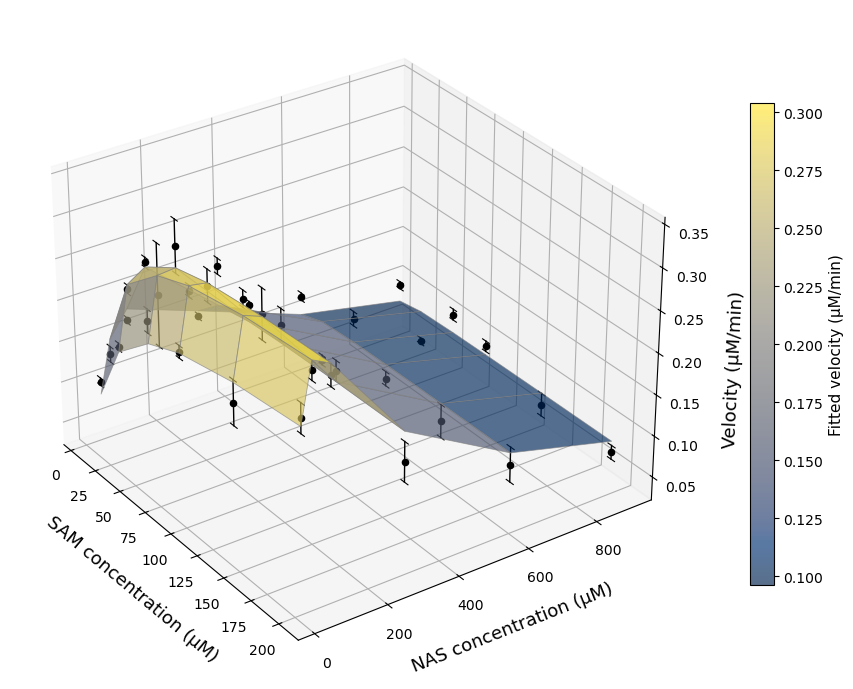

In [9]:
# 3D fitted surface for the selected global kinetic model
#
# Surface:
# prediction from the selected unweighted global model
#
# Black points:
# observed mean velocities
#
# Vertical bars:
# observed mean ± SD

import numpy as np
import matplotlib.pyplot as plt


# Use the model selected in the global fitting

if selected_result is None:
    raise RuntimeError(
        "No selected global model is available."
    )

selected_model = selected_result["Function"]
selected_parameters = selected_result["Parameters"]
selected_model_name = selected_result["Model"]

print(
    "Plotting selected global kinetic model:",
    selected_model_name
)

print(
    "Parameters:",
    selected_parameters
)


# Model predictions on the experimentally measured 6 × 6 grid

Z_fit = selected_model(
    xdata,
    *selected_parameters
).reshape(
    Z.shape
)


# Create 3D figure

fig = plt.figure(
    figsize=(9, 7)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# Fitted model surface
surf = ax.plot_surface(
    X,
    Y,
    Z_fit,
    cmap=plt.cm.cividis,
    alpha=0.65,
    linewidth=0.6,
    edgecolor="gray",
    antialiased=True
)


# Observed mean velocities
ax.scatter(
    X.flatten(),
    Y.flatten(),
    Z.flatten(),
    color="black",
    s=20,
    depthshade=False
)

# Observed SD bars

cap_size = 3.0

for x, y, z, err in zip(
    X.flatten(),
    Y.flatten(),
    Z.flatten(),
    Z_sd.flatten()
):

    z_low = max(
        z - err,
        0.0
    )

    z_high = (
        z + err
    )


    # Vertical SD line
    ax.plot(
        [x, x],
        [y, y],
        [z_low, z_high],
        color="black",
        linewidth=1.0
    )


    # Lower cap
    ax.plot(
        [
            x - cap_size,
            x + cap_size
        ],
        [y, y],
        [z_low, z_low],
        color="black",
        linewidth=0.8
    )


    # Upper cap
    ax.plot(
        [
            x - cap_size,
            x + cap_size
        ],
        [y, y],
        [z_high, z_high],
        color="black",
        linewidth=0.8
    )

# Axis labels

ax.set_xlabel(
    "SAM concentration (µM)",
    fontsize=13,
    labelpad=10
)

ax.set_ylabel(
    "NAS concentration (µM)",
    fontsize=13,
    labelpad=10
)

ax.set_zlabel(
    "Velocity (µM/min)",
    fontsize=13,
    labelpad=10
)

# View

ax.view_init(
    elev=30,
    azim=-35
)

ax.tick_params(
    axis="both",
    labelsize=10
)

# Colorbar

cbar = fig.colorbar(
    surf,
    ax=ax,
    shrink=0.72,
    pad=0.08
)

cbar.set_label(
    "Fitted velocity (µM/min)",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=10
)

# Layout and save

plt.tight_layout()

plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "selected_global_model_surface.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/"
    "selected_global_model_surface.pdf",
    bbox_inches="tight"
)

plt.show()